# Mouse fib/dec pseudotime — explicit root selection

The v2 embedding (induced-only, apoptotic-dropped, retrained scVI) opened up the
dynamic range but scrambled the fibroblast ordering. Hypothesis: **the root was
wrong**, not the embedding.

This notebook makes the root choice **explicit and auditable**, then recomputes DPT.
No scVI retrain, no GPU: it reuses the diffmap already in the object, so each root
candidate is a few seconds.

**How DPT + root works.** `sc.tl.dpt` needs `adata.uns['iroot']` — a single integer
row index. Pseudotime is the diffusion distance from that one cell. So "choosing the
root" = choosing one cell. We evaluate several *principled* ways to pick it and
compare the resulting trajectories on the same axes:

1. **subtype anchor + diffmap-extreme** (the v1/v2 method): among `efib_proliferative`
   cells, take the one nearest / farthest from the global centroid in DC2-DC3.
2. **earliest-timepoint centroid**: the cell closest to the centroid of the earliest
   induced timepoint (`1_dpi_early`).
3. **max-proliferation fibroblast**: the fibroblast with the highest `proliferation`
   score - a biological prior that cycling progenitors sit at trajectory start.
4. **manual index**: paste any obs_name to force a specific root.

For each candidate we report Spearman(pt, day), Spearman(pt, subtype-rank), and the
per-subtype median ordering, so the right root is the one that orders the biology.

In [1]:
import numpy as np, pandas as pd, scanpy as sc, anndata as ad
from scipy.stats import spearmanr
import matplotlib.pyplot as plt

REPO = "/n/lab_storage/eddy_lab/users/nhilgert/xmens_final"
H5AD = f"{REPO}/pseudotime_mouse_v2_induced_no_apop/2026_08_28_mouse_fibdec_pseudotime.h5ad"
CLUSTER_KEY = "cell_subtype"

# v2 vocabulary, ordered fibroblast -> decidual (the biological expectation)
FIB = ["efib_outer", "efib_middle", "efib_middle_induced", "efib_subluminal", "efib_proliferative"]
DEC = ["decidual_boundary", "decidual_proliferative", "decidual_mature"]  # apoptotic dropped in v2
SUBTYPE_ORDER = FIB + DEC
RANK = {s: i for i, s in enumerate(SUBTYPE_ORDER)}

adata = sc.read_h5ad(H5AD)
print(adata.shape)
print("obsm:", list(adata.obsm))
print("has diffmap:", "X_diffmap" in adata.obsm, "| has neighbors:", "neighbors" in adata.uns)
print("current iroot:", adata.uns.get("iroot"))

(32957, 33698)
obsm: ['X_diffmap', 'X_scVI', 'X_spatial', 'X_umap', 'X_umap_scVI']
has diffmap: True | has neighbors: True
current iroot: 14146


## Helper: recompute DPT from a given root and score it

In [2]:
labels = adata.obs[CLUSTER_KEY].astype(str)
day = adata.obs["day"].astype(float).to_numpy()
subrank = labels.map(RANK).to_numpy(dtype=float)   # NaN for any label not in SUBTYPE_ORDER

def recompute_dpt(root_idx):
    "Set the root and recompute DPT on the existing diffmap. Returns pseudotime array."
    adata.uns["iroot"] = int(root_idx)
    sc.tl.dpt(adata)   # uses adata.obsm['X_diffmap'] already present
    return adata.obs["dpt_pseudotime"].to_numpy(float)

def score(pt, name, root_idx):
    ok = np.isfinite(pt) & np.isfinite(day)
    rho_day, p_day = spearmanr(pt[ok], day[ok])
    okr = np.isfinite(pt) & np.isfinite(subrank)
    rho_rank, _ = spearmanr(pt[okr], subrank[okr])
    med = (pd.DataFrame({"s": labels[np.isfinite(pt)], "pt": pt[np.isfinite(pt)]})
           .groupby("s")["pt"].median())
    med_ord = [med.get(s, np.nan) for s in SUBTYPE_ORDER]
    mono = np.all(np.diff([m for m in med_ord if np.isfinite(m)]) > 0)
    row = dict(candidate=name, root_idx=int(root_idx),
               root_subtype=labels.iloc[root_idx], root_day=float(day[root_idx]),
               rho_day=round(float(rho_day), 3), rho_subtype_rank=round(float(rho_rank), 3),
               fibdec_monotonic=bool(mono))
    return row, med

## Candidate roots - each is one explicit, named choice

Edit this cell to add or change strategies. Every candidate resolves to a single
`root_idx`; nothing is hidden.

In [9]:
import numpy as np
import matplotlib.pyplot as plt

# DC2, DC3 = columns 1, 2 (column 0 is the trivial constant component).
dc = adata.obsm["X_diffmap"][:, [1, 2]]
dc2 = dc[:, 0]
labels = adata.obs["cell_subtype"].astype(str)

candidates = {}

# --- 0. global DC2 extreme (geometric — what you've been rooting on) ---
candidates["dc2_max (global)"] = int(dc2.argmin())
candidates["dc2_min (global)"] = int(dc2.argmin())

# --- 1. subtype anchor + diffmap extreme (pipeline method) — mouse only ---
anchor = "efib_proliferative"
amask = (labels == anchor).values
if amask.any():
    acand = np.where(amask)[0]
    centroid_all = dc[~amask].mean(axis=0)
    adist = np.linalg.norm(dc[amask] - centroid_all, axis=1)
    candidates["anchor_near (v2 method)"] = int(acand[adist.argmin()])
    candidates["anchor_far"]              = int(acand[adist.argmax()])
else:
    print(f"skip: anchor {anchor!r} absent (expected for human)")

# --- 2. earliest-timepoint centroid (whatever the earliest is) ---
day = adata.obs["day"].astype(float)
emask = (day == day.min()).values
if emask.any():
    ecand = np.where(emask)[0]
    ecentroid = dc[emask].mean(axis=0)
    edist = np.linalg.norm(dc[emask] - ecentroid, axis=1)
    candidates[f"earliest_tp_centroid (day={day.min():g})"] = int(ecand[edist.argmin()])

# --- 3. max-proliferation fibroblast (cycling progenitor = start) ---
if "proliferation" in adata.obs.columns:
    fibmask = labels.isin(FIB).values
    prolif = adata.obs["proliferation"].to_numpy(float)
    pf = np.where(fibmask & np.isfinite(prolif))[0]
    if pf.size:
        candidates["max_prolif_fibroblast"] = int(pf[np.argmax(prolif[pf])])
    else:
        print("skip: no finite proliferation among fibroblasts")
else:
    print("skip: no 'proliferation' column")

# --- 4. current object root, for reference ---
if "iroot" in adata.uns:
    candidates["current_object_root"] = int(adata.uns["iroot"])

print()
for k, v in candidates.items():
    print(f"{k:32s} idx={v:6d}  subtype={labels.iloc[v]:22s}  "
          f"tp={adata.obs['timepoint'].iloc[v]}  DC2={dc2[v]:+.5f}")


dc2_max (global)                 idx=  6878  subtype=efib_outer              tp=1_dpi_late  DC2=-0.01105
dc2_min (global)                 idx=  6878  subtype=efib_outer              tp=1_dpi_late  DC2=-0.01105
anchor_near (v2 method)          idx= 10315  subtype=efib_proliferative      tp=1_dpi_late  DC2=-0.00152
anchor_far                       idx=  6872  subtype=efib_proliferative      tp=1_dpi_late  DC2=-0.00740
earliest_tp_centroid (day=1)     idx=  2354  subtype=decidual_boundary       tp=1_dpi_early  DC2=-0.00311
max_prolif_fibroblast            idx=  6766  subtype=efib_outer              tp=1_dpi_late  DC2=-0.00771
current_object_root              idx=  6766  subtype=efib_outer              tp=1_dpi_late  DC2=-0.00771


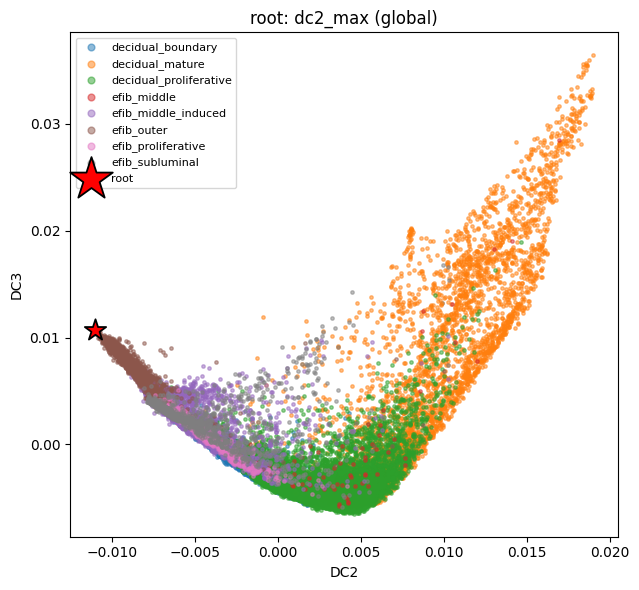

chosen root: dc2_max (global)
  obs index = 6878
  obs_name  = CCGGTGATCGGTAGGA-1-1_dpi_late_mck12a
  timepoint = 1_dpi_late
  day       = 1.5
  cell_type = endometrial_fibroblast
  subtype   = efib_outer
  DC2, DC3  = [-0.01104568  0.01068665]


In [10]:
# ---- choose the root ----
choice = "dc2_max (global)"
root_idx = candidates[choice]

# ---- plot in diffusion space with the root starred ----
fig, ax = plt.subplots(figsize=(6.5, 6))
for lab in sorted(labels.unique()):
    m = (labels == lab).values
    ax.scatter(dc[m, 0], dc[m, 1], s=6, alpha=0.5, label=lab)
ax.scatter(dc[root_idx, 0], dc[root_idx, 1],
           s=260, c="red", marker="*", edgecolor="black",
           linewidth=1.3, zorder=5, label="root")
ax.set_xlabel("DC2")
ax.set_ylabel("DC3")
ax.set_title(f"root: {choice}")
ax.legend(markerscale=2, fontsize=8, loc="best")
plt.tight_layout()
plt.show()

# ---- what the root corresponds to ----
print(f"chosen root: {choice}")
print(f"  obs index = {root_idx}")
print(f"  obs_name  = {adata.obs_names[root_idx]}")
print(f"  timepoint = {adata.obs['timepoint'].iloc[root_idx]}")
print(f"  day       = {adata.obs['day'].iloc[root_idx]}")
print(f"  cell_type = {adata.obs['cell_type'].iloc[root_idx]}")
print(f"  subtype   = {labels.iloc[root_idx]}")
print(f"  DC2, DC3  = {dc[root_idx]}")

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

X = adata.obsm["X_diffmap"]
labels = adata.obs["cell_subtype"].astype(str)
pt = adata.obs["dpt_pseudotime"].to_numpy()

# Which DC pairs to show. (col_x, col_y) as X_diffmap columns; label n = column n-1.
# Default: DC2 vs DC3, DC2 vs DC4, DC3 vs DC4, DC2 vs DC5.
pairs = [(1, 2), (1, 3), (2, 3), (1, 4)]

# guard against asking for a component the matrix doesn't have
n_comps = X.shape[1]
pairs = [(a, b) for (a, b) in pairs if a < n_comps and b < n_comps]
def dc_name(col): return f"DC{col + 1}"

ncol = 2
nrow = int(np.ceil(len(pairs) / ncol))

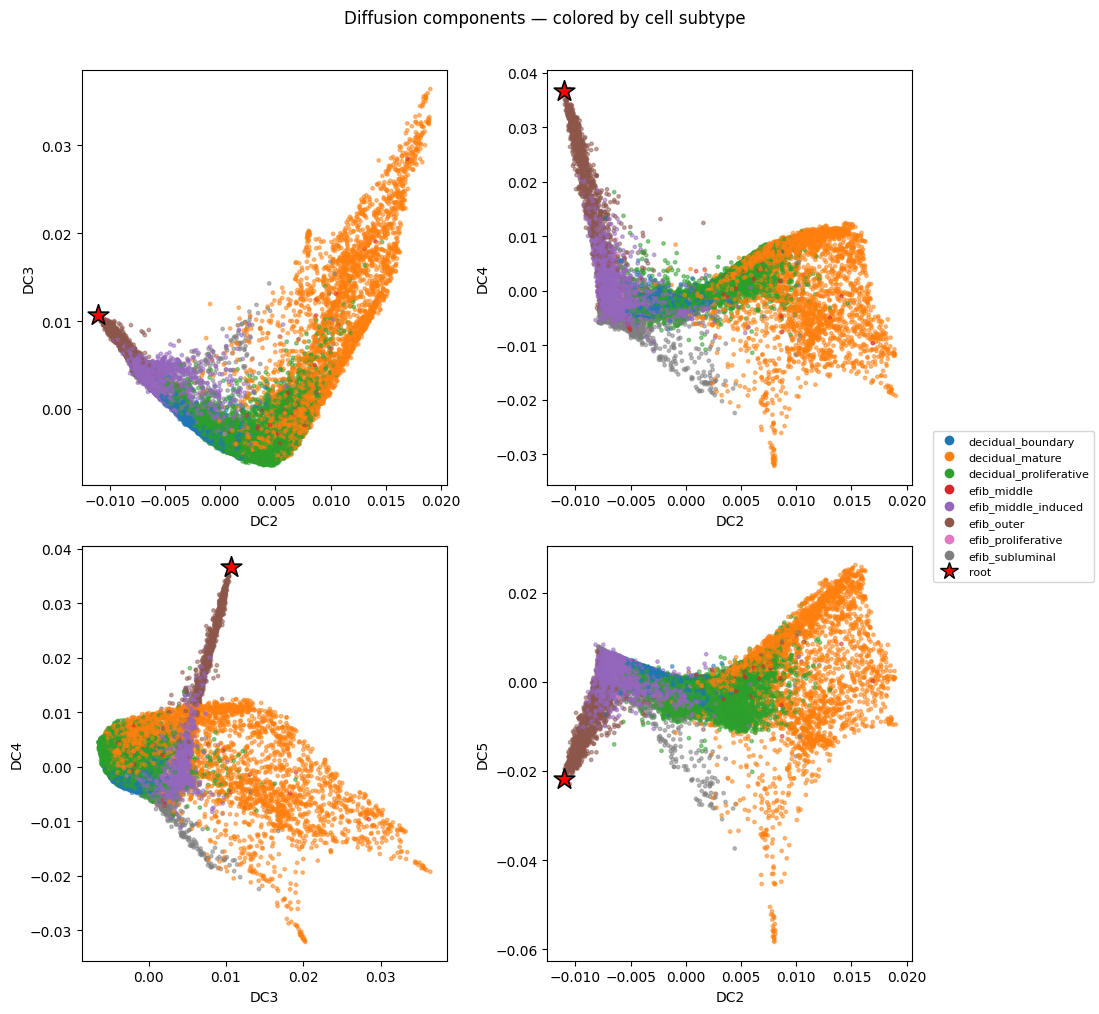

In [17]:
cats = sorted(labels.unique())
cmap = plt.get_cmap("tab10" if len(cats) <= 10 else "tab20")
color_of = {c: cmap(i % cmap.N) for i, c in enumerate(cats)}
pt_colors = labels.map(color_of).to_numpy()

fig, axes = plt.subplots(nrow, ncol, figsize=(5.5 * ncol, 5 * nrow), squeeze=False)
for ax, (cx, cy) in zip(axes.ravel(), pairs):
    ax.scatter(X[:, cx], X[:, cy], c=pt_colors, s=6, alpha=0.5)
    ax.scatter(X[root_idx, cx], X[root_idx, cy], s=240, c="red",
               marker="*", edgecolor="black", linewidth=1.2, zorder=5)
    ax.set_xlabel(dc_name(cx)); ax.set_ylabel(dc_name(cy))
for ax in axes.ravel()[len(pairs):]:
    ax.axis("off")

handles = [Line2D([0], [0], marker="o", linestyle="", markersize=7,
                  markerfacecolor=color_of[c], markeredgecolor="none", label=c)
           for c in cats]
handles.append(Line2D([0], [0], marker="*", linestyle="", markersize=13,
                      markerfacecolor="red", markeredgecolor="black", label="root"))
fig.legend(handles=handles, loc="center right", fontsize=8, markerscale=1)
fig.suptitle("Diffusion components — colored by cell subtype", y=1.01)
fig.tight_layout(rect=[0, 0, 0.86, 1])
plt.show()

## Evaluate every candidate and rank them

In [4]:
rows, meds = [], {}
for name, idx in candidates.items():
    pt = recompute_dpt(idx)
    row, med = score(pt, name, idx)
    rows.append(row); meds[name] = med

summary = pd.DataFrame(rows).set_index("candidate")
summary = summary.sort_values("rho_subtype_rank", ascending=False)
print("Ranked by subtype-rank correlation (higher = biology better ordered):\n")
print(summary.to_string())

Ranked by subtype-rank correlation (higher = biology better ordered):

                         root_idx        root_subtype  root_day  rho_day  rho_subtype_rank  fibdec_monotonic
candidate                                                                                                   
max_prolif_fibroblast        6766          efib_outer       1.5    0.414             0.829             False
anchor_far                   1295  efib_proliferative       1.0    0.452             0.785             False
earliest_tp_centroid         1374  efib_proliferative       1.0    0.470             0.532             False
anchor_near (v2 method)     14146  efib_proliferative       2.0    0.308             0.402             False
current_object_root         14146  efib_proliferative       2.0    0.308             0.402             False


## Per-subtype median ordering for the top candidate

The winning root is the one where the fib->dec medians increase monotonically **and**
the day/subtype correlations are high. This plot makes the ordering visible.

Top candidate: max_prolif_fibroblast



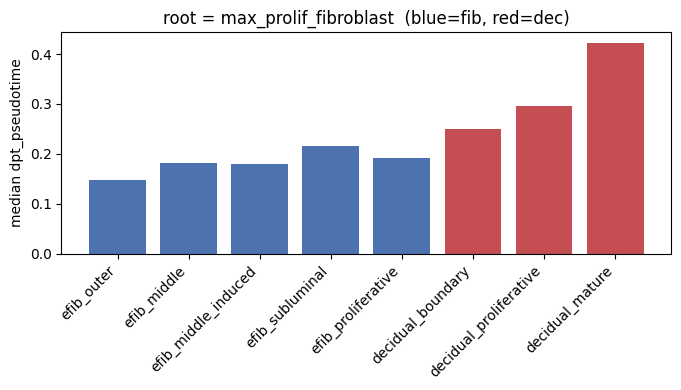

In [5]:
best = summary.index[0]
print(f"Top candidate: {best}\n")
med = meds[best].reindex(SUBTYPE_ORDER)
fig, ax = plt.subplots(figsize=(7, 4))
colors = ["#4C72B0"]*len(FIB) + ["#C44E52"]*len(DEC)
ax.bar(range(len(SUBTYPE_ORDER)), med.values, color=colors)
ax.set_xticks(range(len(SUBTYPE_ORDER))); ax.set_xticklabels(SUBTYPE_ORDER, rotation=45, ha="right")
ax.set_ylabel("median dpt_pseudotime"); ax.set_title(f"root = {best}  (blue=fib, red=dec)")
fig.tight_layout()
fig.savefig("root_choice_subtype_ordering.png", dpi=150)
plt.show()

## Commit the chosen root

Set `CHOSEN` to the candidate you want (or a manual obs_name), recompute DPT one final
time, and write the pseudotime back. This is the **only** cell that mutates the object,
and it writes a *_rooted.h5ad copy - it does not overwrite the deliverable.

In [6]:
CHOSEN = best                      # <-- change to any key in `candidates`, or set CHOSEN_OBSNAME below
CHOSEN_OBSNAME = None              # <-- or paste an obs_name string to force a specific root cell

if CHOSEN_OBSNAME is not None:
    root_idx = int(adata.obs_names.get_loc(CHOSEN_OBSNAME))
    root_desc = f"manual obs_name {CHOSEN_OBSNAME}"
else:
    root_idx = candidates[CHOSEN]
    root_desc = f"{CHOSEN} (idx {root_idx})"

pt = recompute_dpt(root_idx)
row, _ = score(pt, CHOSEN, root_idx)
print("committed root:", root_desc)
print("  root subtype:", labels.iloc[root_idx], "| root day:", day[root_idx])
print("  rho(pt,day) =", row["rho_day"], "| rho(pt,subtype_rank) =", row["rho_subtype_rank"],
      "| fib->dec monotonic:", row["fibdec_monotonic"])

adata.obs["dpt_pseudotime"] = pt
adata.obs["dpt_pseudotime_root"] = root_desc
out = f"{REPO}/pseudotime_mouse_v2_induced_no_apop/2026_08_28_mouse_fibdec_pseudotime_rooted.h5ad"
adata.write_h5ad(out)
print("wrote", out)

committed root: max_prolif_fibroblast (idx 6766)
  root subtype: efib_outer | root day: 1.5
  rho(pt,day) = 0.414 | rho(pt,subtype_rank) = 0.829 | fib->dec monotonic: False
wrote /n/lab_storage/eddy_lab/users/nhilgert/xmens_final/pseudotime_mouse_v2_induced_no_apop/2026_08_28_mouse_fibdec_pseudotime_rooted.h5ad


In [11]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

# --- DPT on the chosen root ---
adata.uns["iroot"] = root_idx
sc.tl.dpt(adata)

pt = adata.obs["dpt_pseudotime"]
print(f"root: idx={root_idx}  subtype={labels.iloc[root_idx]}  "
      f"tp={adata.obs['timepoint'].iloc[root_idx]}")
print(f"pseudotime [{pt.min():.4f}, {pt.max():.4f}]  "
      f"non-finite={int((~np.isfinite(pt)).sum())}")
print(f"pseudotime at root (should be ~0): {pt.iloc[root_idx]:.6f}")

# orientation check — the meaningful one for human
day_num = adata.obs["day"].astype(float).to_numpy()
ok = np.isfinite(pt.to_numpy()) & np.isfinite(day_num)
rho, p = spearmanr(day_num[ok], pt.to_numpy()[ok])
print(f"Spearman(day, pseudotime) = {rho:+.4f}  p={p:.3e}   "
      f"({'OK' if rho > 0 else 'INVERTED — consider the min-DC2 root'})")

root: idx=6878  subtype=efib_outer  tp=1_dpi_late
pseudotime [0.0000, 1.0000]  non-finite=0
pseudotime at root (should be ~0): 0.000000
Spearman(day, pseudotime) = +0.3910  p=0.000e+00   (OK)


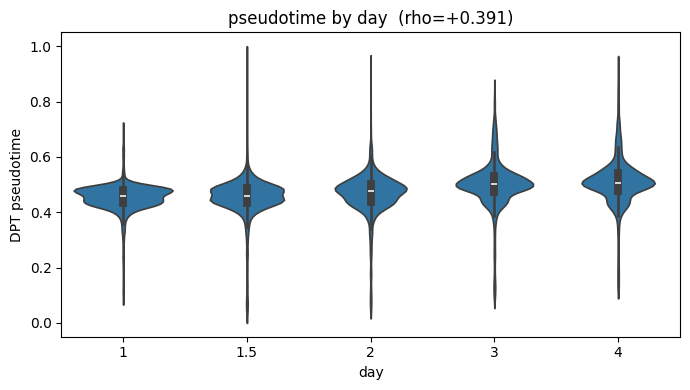

/tmp/ipykernel_1099640/2088468315.py:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")


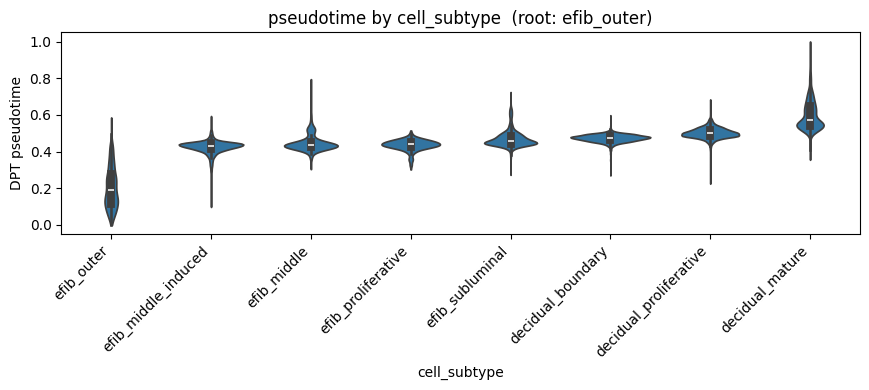

In [12]:
# --- violin by day ---
fig, ax = plt.subplots(figsize=(7, 4))
day_order = [f"{d:g}" for d in sorted(adata.obs["day"].astype(float).unique())]
df_day = pd.DataFrame({
    "day": adata.obs["day"].astype(float).map(lambda d: f"{d:g}").values,
    "dpt_pseudotime": pt.values,
})
sns.violinplot(data=df_day, x="day", y="dpt_pseudotime", order=day_order, cut=0, ax=ax)
ax.set_xlabel("day"); ax.set_ylabel("DPT pseudotime")
ax.set_title(f"pseudotime by day  (rho={rho:+.3f})")
fig.tight_layout()
plt.show()

# --- violin by cell type ---
# use fine subtypes if present, else fall back to cell_type (human)
celltype_col = "cell_subtype" if labels.nunique() > 2 else "cell_type"
ct = adata.obs[celltype_col].astype(str)
# order by median pseudotime so the trajectory reads left→right
ct_order = (pd.DataFrame({"ct": ct.values, "pt": pt.values})
            .groupby("ct")["pt"].median().sort_values().index.tolist())

fig, ax = plt.subplots(figsize=(max(7, 1.1*len(ct_order)), 4))
df_ct = pd.DataFrame({"cell_type": ct.values, "dpt_pseudotime": pt.values})
sns.violinplot(data=df_ct, x="cell_type", y="dpt_pseudotime", order=ct_order, cut=0, ax=ax)
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
ax.set_xlabel(celltype_col); ax.set_ylabel("DPT pseudotime")
ax.set_title(f"pseudotime by {celltype_col}  (root: {labels.iloc[root_idx]})")
fig.tight_layout()
plt.show()

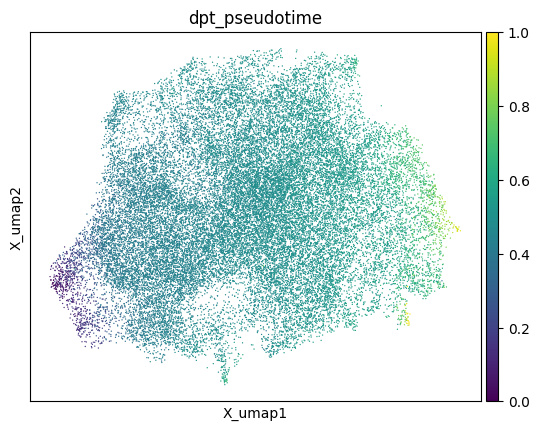

In [15]:
sc.pl.embedding(adata, basis = "X_umap", color = 'dpt_pseudotime')

In [18]:
!uv pip install palantir

/usr/bin/sh: uv: command not found


In [21]:
# pip install palantir  --break-system-packages   # if not already installed
import palantir
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

# Palantir's early_cell is an obs_NAME (string), not a positional index.
# root_idx is positional → convert.
early_cell = adata.obs_names[root_idx]
print(f"early cell: {early_cell}  "
      f"(subtype={adata.obs['cell_subtype'].iloc[root_idx]}, "
      f"tp={adata.obs['timepoint'].iloc[root_idx]})")

day_num = adata.obs["day"].astype(float).to_numpy()
def orient(pt, name):
    v = np.asarray(pt, float)
    ok = np.isfinite(v) & np.isfinite(day_num)
    rho, p = spearmanr(day_num[ok], v[ok])
    print(f"  {name}: Spearman(day, pt)={rho:+.4f} p={p:.2e}  "
          f"range [{np.nanmin(v):.3f}, {np.nanmax(v):.3f}]  "
          f"{'OK' if rho > 0 else 'INVERTED'}")
    return rho

early cell: CCGGTGATCGGTAGGA-1-1_dpi_late_mck12a  (subtype=efib_outer, tp=1_dpi_late)


In [23]:
# your RTK-derived eigenbasis as Palantir's multiscale space (drop trivial DC1)
ms_rtk = pd.DataFrame(
    adata.obsm["X_diffmap"][:, 1:],
    index=adata.obs_names,
    columns=[f"DC{i+1}" for i in range(1, adata.obsm["X_diffmap"].shape[1])],
)

pr_rtk = palantir.core.run_palantir(
    ms_rtk,
    early_cell=early_cell,
    num_waypoints=1200,
    seed=0,
    use_early_cell_as_start=True,
)
adata.obs["palantir_pt_rtk"] = pr_rtk.pseudotime.reindex(adata.obs_names).to_numpy()
adata.obs["palantir_entropy_rtk"] = pr_rtk.entropy.reindex(adata.obs_names).to_numpy()
orient(adata.obs["palantir_pt_rtk"], "RTK")

Sampling and flocking waypoints...
Time for determining waypoints: 0.0007200360298156739 minutes
Determining pseudotime...
Shortest path distances using 30-nearest neighbor graph...
Time for shortest paths: 0.24450265169143676 minutes
Iteratively refining the pseudotime...
Correlation at iteration 1: 0.9850
Correlation at iteration 2: 0.9996
Correlation at iteration 3: 1.0000
Entropy and branch probabilities...
Markov chain construction...
Identification of terminal states...
Computing fundamental matrix and absorption probabilities...
Project results to all cells...
  RTK: Spearman(day, pt)=+0.4250 p=0.00e+00  range [0.000, 1.000]  OK


np.float64(0.42497240683079784)

In [ ]:
# Palantir builds its own diffusion map from the scVI latent
dm = palantir.utils.run_diffusion_maps(
    pd.DataFrame(adata.obsm["X_scVI"], index=adata.obs_names),
    n_components=10,
    knn=30,
)
ms_std = palantir.utils.determine_multiscale_space(dm)

In [25]:
pr_std = palantir.core.run_palantir(
    ms_std,
    early_cell=early_cell,
    num_waypoints=1200,
    seed=0,
    use_early_cell_as_start=True,
)
adata.obs["palantir_pt_std"] = pr_std.pseudotime.reindex(adata.obs_names).to_numpy()
adata.obs["palantir_entropy_std"] = pr_std.entropy.reindex(adata.obs_names).to_numpy()
orient(adata.obs["palantir_pt_std"], "standard")

Sampling and flocking waypoints...
Time for determining waypoints: 0.00024071931838989257 minutes
Determining pseudotime...
Shortest path distances using 30-nearest neighbor graph...
Time for shortest paths: 0.28796865542729694 minutes
Iteratively refining the pseudotime...
Correlation at iteration 1: 0.9999
Entropy and branch probabilities...
Markov chain construction...
Identification of terminal states...
Computing fundamental matrix and absorption probabilities...
Project results to all cells...
  standard: Spearman(day, pt)=+0.4075 p=0.00e+00  range [0.000, 1.000]  OK


np.float64(0.4075316490859476)

[rtk] Spearman(day, pt)=+0.4250  p=0.00e+00  (OK)


/tmp/ipykernel_1099640/3371813446.py:42: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, ha="right")


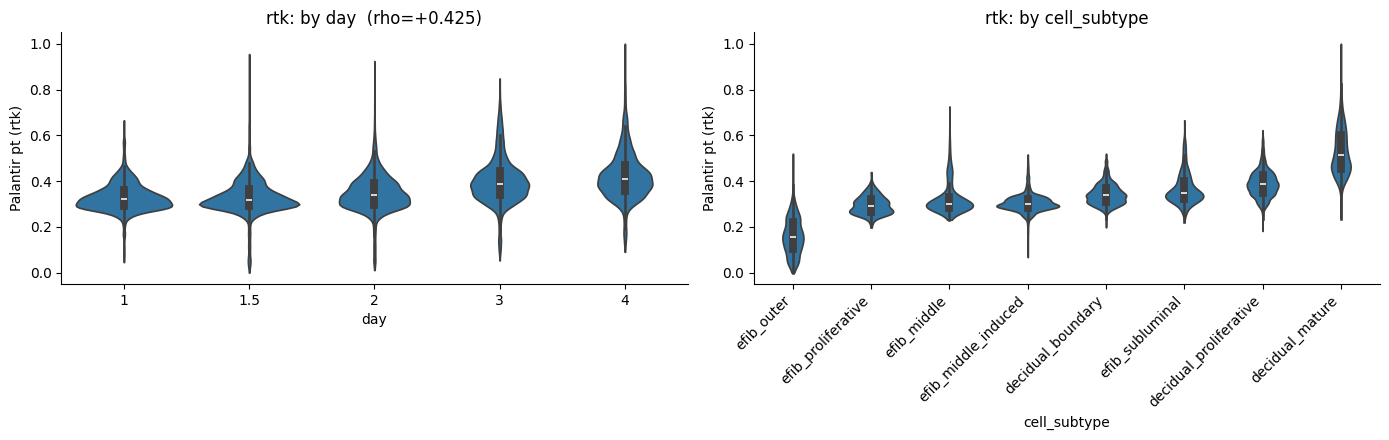

[std] Spearman(day, pt)=+0.4075  p=0.00e+00  (OK)


/tmp/ipykernel_1099640/3371813446.py:42: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, ha="right")


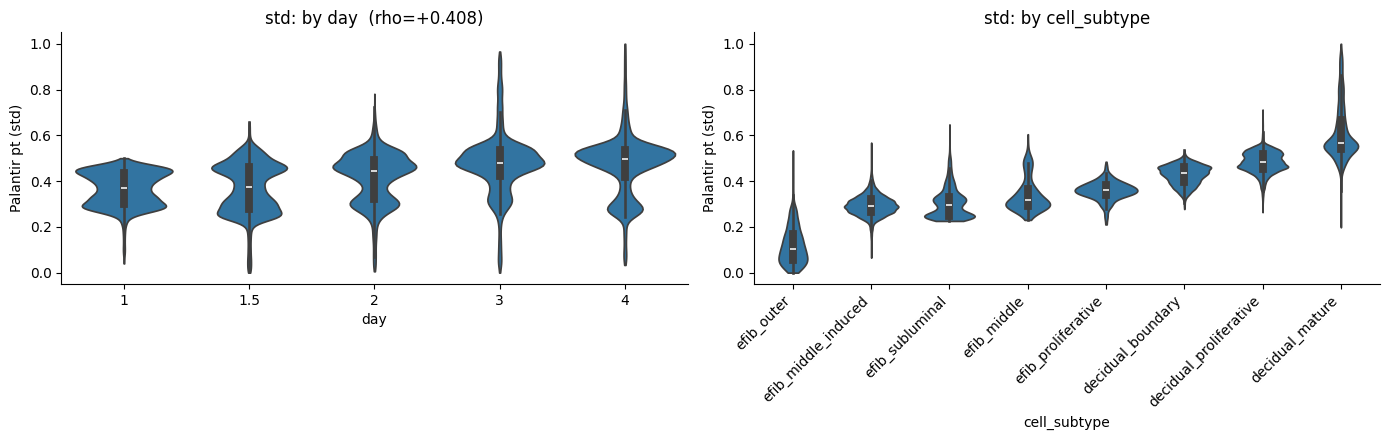

In [26]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

# whichever Palantir runs completed
pt_cols = [c for c in ["palantir_pt_rtk", "palantir_pt_std"] if c in adata.obs]
assert pt_cols, "no palantir_pt_* columns found — run a Palantir cell first"

labels = adata.obs["cell_subtype"].astype(str)
day_num = adata.obs["day"].astype(float)
day_order = [f"{d:g}" for d in sorted(day_num.unique())]
day_str = day_num.map(lambda d: f"{d:g}")

# fine subtypes if present (mouse), else coarse cell_type (human)
celltype_col = "cell_subtype" if labels.nunique() > 2 else "cell_type"
ct = adata.obs[celltype_col].astype(str)

for col in pt_cols:
    pt = adata.obs[col]
    tag = col.replace("palantir_pt_", "")

    # orientation, printed above each pair
    ok = np.isfinite(pt.to_numpy()) & np.isfinite(day_num.to_numpy())
    rho, p = spearmanr(day_num.to_numpy()[ok], pt.to_numpy()[ok])
    print(f"[{tag}] Spearman(day, pt)={rho:+.4f}  p={p:.2e}  "
          f"({'OK' if rho > 0 else 'INVERTED'})")

    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

    # by day
    df_day = pd.DataFrame({"day": day_str.values, "pt": pt.values})
    sns.violinplot(data=df_day, x="day", y="pt", order=day_order, cut=0, ax=axes[0])
    axes[0].set_xlabel("day"); axes[0].set_ylabel(f"Palantir pt ({tag})")
    axes[0].set_title(f"{tag}: by day  (rho={rho:+.3f})")

    # by cell type, ordered by median pt so the trajectory reads left→right
    df_ct = pd.DataFrame({"ct": ct.values, "pt": pt.values})
    ct_order = df_ct.groupby("ct")["pt"].median().sort_values().index.tolist()
    sns.violinplot(data=df_ct, x="ct", y="pt", order=ct_order, cut=0, ax=axes[1])
    axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, ha="right")
    axes[1].set_xlabel(celltype_col); axes[1].set_ylabel(f"Palantir pt ({tag})")
    axes[1].set_title(f"{tag}: by {celltype_col}")

    plt.tight_layout()
    plt.show()

In [27]:
rank_map = {s: i for i, s in enumerate(SUBTYPE_ORDER)}
ranks = adata.obs["cell_subtype"].astype(str).map(rank_map).to_numpy(float)

for col in ["dpt_pseudotime", "palantir_pt_rtk", "palantir_pt_std"]:
    if col not in adata.obs:
        continue
    pt = adata.obs[col].to_numpy(float)
    ok = np.isfinite(pt) & np.isfinite(ranks)
    rho_r, _ = spearmanr(pt[ok], ranks[ok])
    rho_d, _ = spearmanr(pt[ok], adata.obs["day"].astype(float).to_numpy()[ok])
    print(f"{col:20s}  rho(subtype_rank)={rho_r:+.4f}  rho(day)={rho_d:+.4f}")

dpt_pseudotime        rho(subtype_rank)=+0.8394  rho(day)=+0.3910
palantir_pt_rtk       rho(subtype_rank)=+0.7438  rho(day)=+0.4250
palantir_pt_std       rho(subtype_rank)=+0.8715  rho(day)=+0.4075
